# 04 — Adding an agent

This tutorial has two independent result sets: the single-objective example in `model`, and the weighted multi-objective example in `multiple-objective/model`.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

tutorial_dir = Path(r"C:\Users\abduq\Desktop\SSD\MUSE-Tutorials\04-Adding-an-agent")
single_capacity = pd.read_csv(tutorial_dir / "model" / "Results" / "MCACapacity.csv")
multiple_capacity = pd.read_csv(
    tutorial_dir / "multiple-objective" / "model" / "Results" / "MCACapacity.csv"
)
display(single_capacity.head())
display(multiple_capacity.head())

,agent,capacity,dst_region,installed,region,sector,technology,type,year
0,A1,5.0,r1,2020,r1,residential,gasboiler,newcapa,2020
1,A2,5.0,r1,2020,r1,residential,gasboiler,newcapa,2020
2,A1,0.5,r1,2020,r1,power,gasCCGT,newcapa,2020
3,A2,0.5,r1,2020,r1,power,gasCCGT,newcapa,2020
4,A1,7.5,r1,2020,r1,gas,gassupply1,newcapa,2020


,agent,capacity,dst_region,installed,region,sector,technology,type,year
0,A1,5.0,r1,2020,r1,residential,gasboiler,newcapa,2020
1,A2,5.0,r1,2020,r1,residential,gasboiler,newcapa,2020
2,A1,0.5,r1,2020,r1,power,gasCCGT,newcapa,2020
3,A2,0.5,r1,2020,r1,power,gasCCGT,newcapa,2020
4,A1,7.5,r1,2020,r1,gas,gassupply1,newcapa,2020


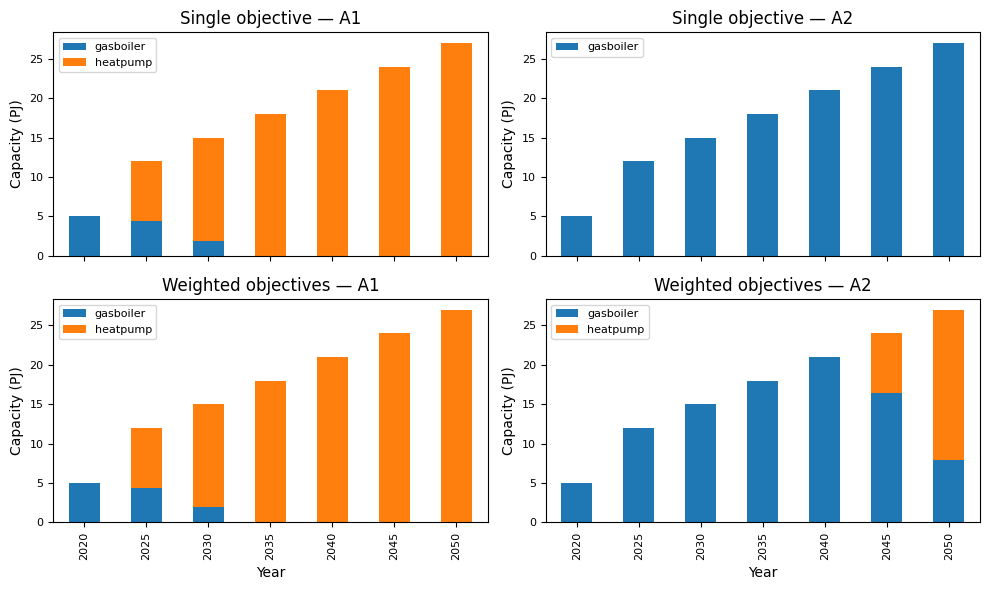

In [4]:
datasets = [
    ("Single objective", single_capacity),
    ("Weighted objectives", multiple_capacity),
]
all_years = sorted(
    set(single_capacity["year"].unique()) | set(multiple_capacity["year"].unique())
)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), squeeze=False, sharex=True)

for row, (scenario_name, data) in enumerate(datasets):
    residential = data[data["sector"] == "residential"]
    for column, agent in enumerate(sorted(residential["agent"].unique())):
        ax = axes[row, column]
        agent_data = residential[residential["agent"] == agent]
        capacity = agent_data.groupby(
            ["year", "technology"], as_index=False
        )["capacity"].sum()
        capacity.pivot(
            index="year", columns="technology", values="capacity"
        ).reindex(all_years, fill_value=0).plot(kind="bar", stacked=True, ax=ax)
        ax.set_title(f"{scenario_name} — {agent}")
        ax.set_ylabel("Capacity (PJ)")
        ax.set_xlabel("Year")
        ax.legend(title=None, prop={"size": 8})
        ax.tick_params(axis="both", labelsize=8)

fig.tight_layout()
fig.savefig(tutorial_dir / "agent_comparison.png", dpi=150, bbox_inches="tight")
plt.show()